___

# Technika Early Stopping u boostingu

## Cvičení: Technika Early Stopping u boostingu

Tento notebook je věnován metodě **early stopping (včasné zastavení)** u boostingového modelu.

**Cíl:**
Pochopit a implementovat early stopping u Gradient Boostingu a sledovat vývoj chyby modelu.

Úkoly:
1. Implementujte algoritmus Gradient Boosting pomocí třídy `GradientBoostingRegressor` z knihovny sklearn.
2. Spusťte boostingový model až s 200 estimátory a měřte chybu na testovacích datech.
3. Implementujte proceduru **early stopping** a vykreslete výkonnost modelu s vyznačením okamžiku zastavení boostingu.


In [1]:
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

import matplotlib.pyplot as plt

/home/lukas/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
np.random.seed(42)

In [3]:
# Data 
np.random.seed(42)
X = np.random.rand(100, 1) - 0.5
y = 3*X[:, 0]**2 + 0.05 * np.random.randn(100)

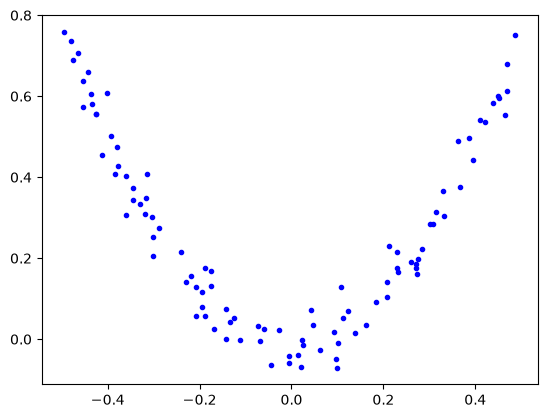

In [4]:
plt.plot(X, y, 'b.')

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=49)

### Model Gradient Boosting – vývoj chyby


**K implementaci:**

`
Algoritmus GradientBoosting:
Inicializuj GradientBoostingRegressor s parametry:
        max_depth = 2
        warm_start = True
        random_state = 42

    Inicializuj train_err jako prázdný seznam
    Inicializuj test_err jako prázdný seznam

    Pro n_estimators od 1 do 199:
        Nastav gbrt.n_estimators na n_estimators
        Natrénuj gbrt pomocí X_train a y_train

        // Výpočet chyby na trénovacích datech
        Predikuj y_train_pred pomocí gbrt na X_train
        Vypočítej train_error jako střední kvadratickou chybu mezi y_train a y_train_pred
        Přidej train_error do seznamu train_err

        // Výpočet chyby na testovacích datech
        Predikuj y_pred pomocí gbrt na X_test
        Vypočítej test_error jako střední kvadratickou chybu mezi y_test a y_pred
        Přidej test_error do seznamu test_err
Konec algoritmu
`


In [28]:
# Měření validační chyby boostingového modelu až pro 200 estimátorů 
gbrt = GradientBoostingRegressor(max_depth=2, warm_start=True, random_state=42)

train_error = [] 
test_error = [] 

for n in range(1, 200): 
    gbrt = GradientBoostingRegressor(max_depth=2, 
                                     n_estimators=n, 
                                     warm_start=True, 
                                     random_state=42)
    
    gbrt.fit(X_train, y_train) 
    # print(f'Fitted on: {n} estimators')
    
    # Výpočet chyby na trénovacích datech
    y_train_pred = gbrt.predict(X_train) 
    train_err = mean_squared_error(y_train, y_train_pred) 
    train_error.append(train_err) 
    # print(train_err)
    
    # Výpočet chyby na testovacích datech 
    y_test_pred = gbrt.predict(X_test) 
    test_err = mean_squared_error(y_test, y_test_pred) 
    test_error.append(test_err) 

In [29]:
# train_error

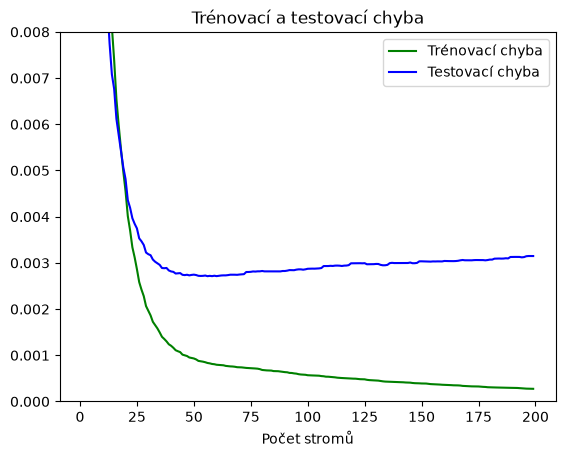

In [30]:
# Vykreslení vývoje validační chyby 
plt.plot(list(range(1, 200)), train_error, 'g-', label='Trénovací chyba')
plt.plot(list(range(1, 200)), test_error, 'b-', label='Testovací chyba')
plt.ylim(0.0, 0.008)
plt.xlabel('Počet stromů')
plt.title('Trénovací a testovací chyba')
plt.legend()

## Kdy zastavit učení modelu?


.

### Implementujte proceduru early stopping s parametrem „nárůst testovací chyby = 5“ a najděte nejlepší model

Zastavte iterativní učení poté, co se testovací chyba modelu zvýší **pětkrát**.


**Early stopping:**

`
Algoritmus EarlyStopping:
    Pokud val_error < min_val_error:
        Nastav min_val_error na val_error
        Nastav error_going_up na 0
    Jinak:
        Zvyš error_going_up o 1
        Pokud se error_going_up rovná 5:
            Ukonči cyklus
Konec algoritmu
`


In [31]:
# Spuštění algoritmu early stopping 
# mean_squared_error(y_test, y_pred)
# min_val_error = float("inf") 
# přidejte error_going_up = 0 

train_error_ = [] 
test_error_ = [] 
min_val_error = float("inf") 
error_going_up = 0 

for n in range(1, 200): 
    gbrt = GradientBoostingRegressor(max_depth=2, 
                                     n_estimators=n, 
                                     warm_start=True, 
                                     random_state=42)
    
    gbrt.fit(X_train, y_train) 
    print(f'Fitted on: {n} estimators')
    
    # Výpočet chyby na trénovacích datech
    y_train_pred = gbrt.predict(X_train) 
    train_err = mean_squared_error(y_train, y_train_pred) 
    train_error_.append(train_err) 
    # print(train_err)
    
    # Výpočet chyby na testovacích datech 
    y_test_pred = gbrt.predict(X_test) 
    test_err = mean_squared_error(y_test, y_test_pred) 
    test_error_.append(test_err) 

    if test_err < min_val_error: 
        min_val_error = test_err
    else: 
        error_going_up += 1 
        if error_going_up == 5:
            break
                

Fitted on: 1 estimators
Fitted on: 2 estimators
Fitted on: 3 estimators
Fitted on: 4 estimators
Fitted on: 5 estimators
Fitted on: 6 estimators
Fitted on: 7 estimators
Fitted on: 8 estimators
Fitted on: 9 estimators
Fitted on: 10 estimators
Fitted on: 11 estimators
Fitted on: 12 estimators
Fitted on: 13 estimators
Fitted on: 14 estimators
Fitted on: 15 estimators
Fitted on: 16 estimators
Fitted on: 17 estimators
Fitted on: 18 estimators
Fitted on: 19 estimators
Fitted on: 20 estimators
Fitted on: 21 estimators
Fitted on: 22 estimators
Fitted on: 23 estimators
Fitted on: 24 estimators
Fitted on: 25 estimators
Fitted on: 26 estimators
Fitted on: 27 estimators
Fitted on: 28 estimators
Fitted on: 29 estimators
Fitted on: 30 estimators
Fitted on: 31 estimators
Fitted on: 32 estimators
Fitted on: 33 estimators
Fitted on: 34 estimators
Fitted on: 35 estimators
Fitted on: 36 estimators
Fitted on: 37 estimators
Fitted on: 38 estimators
Fitted on: 39 estimators
Fitted on: 40 estimators
Fitted on

In [21]:
print(gbrt.n_estimators)

49


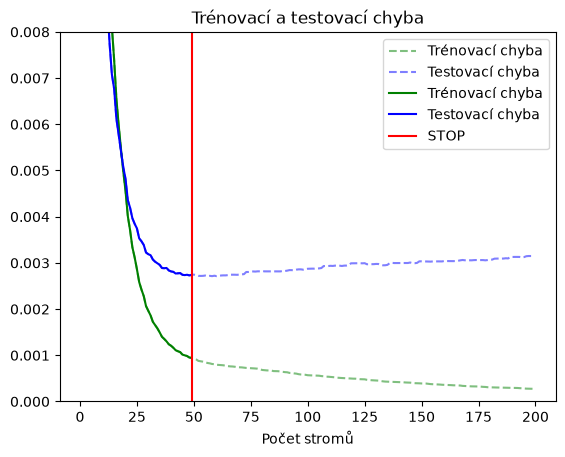

In [32]:
# Vykreslení vývoje validační chyby 
plt.plot(list(range(1, 200)), train_error, 'g--', label='Trénovací chyba', alpha=0.5)
plt.plot(list(range(1, 200)), test_error, 'b--', label='Testovací chyba', alpha=0.5)
plt.plot(list(range(1, gbrt.n_estimators + 1)), train_error_, 'g-', label='Trénovací chyba')
plt.plot(list(range(1, gbrt.n_estimators + 1)), test_error_, 'b-', label='Testovací chyba')
plt.axvline(gbrt.n_estimators, color = 'red', label = 'STOP')
plt.ylim(0.0, 0.008)
plt.xlabel('Počet stromů')
plt.title('Trénovací a testovací chyba')
plt.legend()

In [ ]:
# data pro vykreslení modelu 
X_sim = np.linspace(-0.5, 0.5, 100)
pass 

In [ ]:
# Graf predikce modelu 
pass 
# vykreslení dat 
# vykreslení modelu 